In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")



PROGRAMACION PYTHON AVANZADO - UPSO <br>
PROYECTO 2: Regresion lineal multiple <br>
INTEGRANTES: Carluccio Ros Bruno & Gonzalez Agustin <br>
DATASET: sample_10k_rows.csv <br>
OBSERVACIONES: El dataset seleccionado es una lista de personas de las cuales conocemos datos (edad, ingreso ahorro, habitos, etc) utilizando regresion lineal multiple buscamos mediante esos datos, estimar o predecir el patrimonio neto de la persona (net_worth)

1. Carga de Datos y visualización de variables.

filas y columnas del csv: (10000, 274)
Visualizacion de datos    age  years_of_experience  education_years  weekly_work_hours  \
0   40                   18               11               47.2   
1   62                   40               16               47.1   
2   37                   18               12               30.2   
3   68                   48               16               45.7   
4   52                   30               17               36.8   

   total_annual_income  annual_savings   net_worth  
0            205681.50        38223.18  1274760.87  
1            390874.76       103246.85  2333567.29  
2             37865.76        23792.70   709585.99  
3            263991.84        50110.99  3507891.61  
4            107218.25        27253.37  5747999.55  
Descripcion               age  years_of_experience  education_years  weekly_work_hours  \
count  10000.0000         10000.000000     10000.000000       10000.000000   
mean      53.3382            30.461700        15.

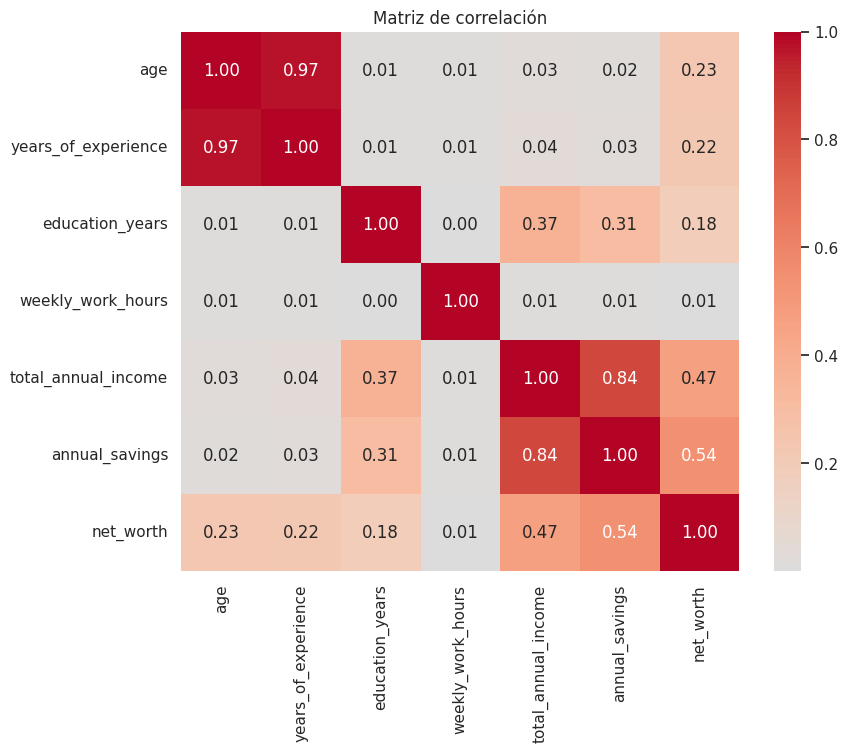

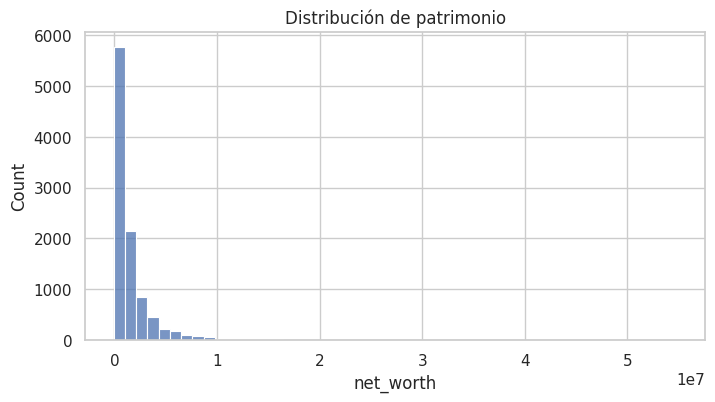

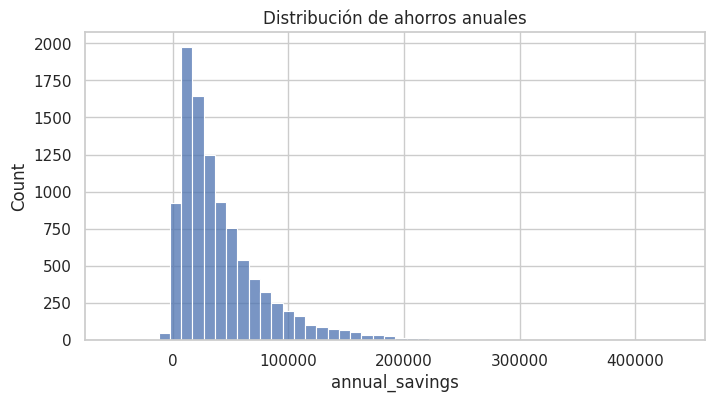

In [14]:
df = pd.read_csv("sample_10k_rows.csv")
print("filas y columnas del csv:", df.shape)
df.head()
df.describe()

# variable que quiero predecir (target) y variables con las que la predigo (entrada)
colTarget = "net_worth" #PATRIMONIO NETO
colEntrada = ["age", "years_of_experience", "education_years",
              "weekly_work_hours", "total_annual_income", "annual_savings"]

# me quedo solo con esas columnas y saco filas con nulos (en estas columnas no hay)
datos = df[colEntrada + [colTarget]].dropna()
print("Visualizacion de datos", datos.head())
print("Descripcion", datos.describe())


# correlación entre variables
plt.figure(figsize=(9, 7))
sns.heatmap(datos.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación"); plt.show()

# histograma del target: se ve que hay muchos patrimonios chicos y pocos enormes
plt.figure(figsize=(8, 4))
sns.histplot(datos["net_worth"], bins=50)
plt.title("Distribución de patrimonio")
plt.show()

# histograma de variable de entrada
plt.figure(figsize=(8, 4))
sns.histplot(datos["annual_savings"], bins=50)
plt.title("Distribución de ahorros anuales")
plt.show()


2. Cambio de estructura de datos a matricial

In [15]:
# matriz con una fila por persona y una columna por variable de entrada
matrizX = datos[colEntrada].to_numpy()
# vector con el patrimonio de cada persona
vectorY = datos[colTarget].to_numpy()
print("forma de X:", matrizX.shape)
print("forma de y:", vectorY.shape)


forma de X: (10000, 6)
forma de y: (10000,)


3. Particionado de datos en Entrenamiento y Test

In [16]:
# random_state fija el sorteo para que dé siempre lo mismo
xTrain, xTest, yTrain, yTest = train_test_split(
    matrizX, vectorY, test_size=0.2, random_state=42)
print("train:", xTrain.shape[0], "filas | test:", xTest.shape[0], "filas")



train: 8000 filas | test: 2000 filas


4. Generación del modelo con los datos de Entrenamiento

In [17]:
# fit busca los coeficientes que minimizan el error cuadrático en train
modelo = LinearRegression()
modelo.fit(xTrain, yTrain)

print("intercepto:", round(modelo.intercept_, 2))
tablaCoef = pd.DataFrame({
    "variable": colEntrada,
    "coeficiente": modelo.coef_,
    # coeficiente por desvío de la variable: sirve para comparar variables
    # que están en unidades distintas (años vs dólares)
    "coefEstandarizado": modelo.coef_ * xTrain.std(axis=0),
})
print(tablaCoef.sort_values("coefEstandarizado", key=abs, ascending=False).round(2))


intercepto: -2323890.05
              variable  coeficiente  coefEstandarizado
5       annual_savings        32.33         1322240.08
0                  age     52412.70          725211.24
4  total_annual_income         1.47          167790.40
1  years_of_experience    -12377.73         -152779.85
3    weekly_work_hours     -1380.05          -12154.57
2      education_years       834.05            2383.86


5. Evaluación del modelo con los datos de Entrenamiento

In [18]:
predTrain = modelo.predict(xTrain)
maeTrain = mean_absolute_error(yTrain, predTrain)
rmseTrain = mean_squared_error(yTrain, predTrain) ** 0.5
r2Train = r2_score(yTrain, predTrain)
print(f"MAE train:  {maeTrain:,.0f}")
print(f"RMSE train: {rmseTrain:,.0f}")
print(f"R2 train:   {r2Train:.3f}")


MAE train:  1,056,793
RMSE train: 2,164,709
R2 train:   0.351


6. Evaluación del modelo con los datos de Test

In [19]:
predTest = modelo.predict(xTest)
maeTest = mean_absolute_error(yTest, predTest)
rmseTest = mean_squared_error(yTest, predTest) ** 0.5
r2Test = r2_score(yTest, predTest)
print(f"MAE test:  {maeTest:,.0f}")
print(f"RMSE test: {rmseTest:,.0f}")
print(f"R2 test:   {r2Test:.3f}")

# comparo contra el modelo más simple: predecir siempre el promedio de train
maeBase = mean_absolute_error(yTest, np.full(len(yTest), yTrain.mean()))
print(f"MAE prediciendo siempre el promedio: {maeBase:,.0f}")

# tabla comparativa train vs test
print(pd.DataFrame({
    "MAE": [maeTrain, maeTest],
    "RMSE": [rmseTrain, rmseTest],
    "R2": [r2Train, r2Test],
}, index=["train", "test"]).round(3))

MAE test:  1,059,490
RMSE test: 2,132,691
R2 test:   0.299
MAE prediciendo siempre el promedio: 1,405,860
               MAE         RMSE     R2
train  1056792.507  2164709.022  0.351
test   1059490.353  2132690.989  0.299


7. Visualizacion de graficos: reales vs predichos

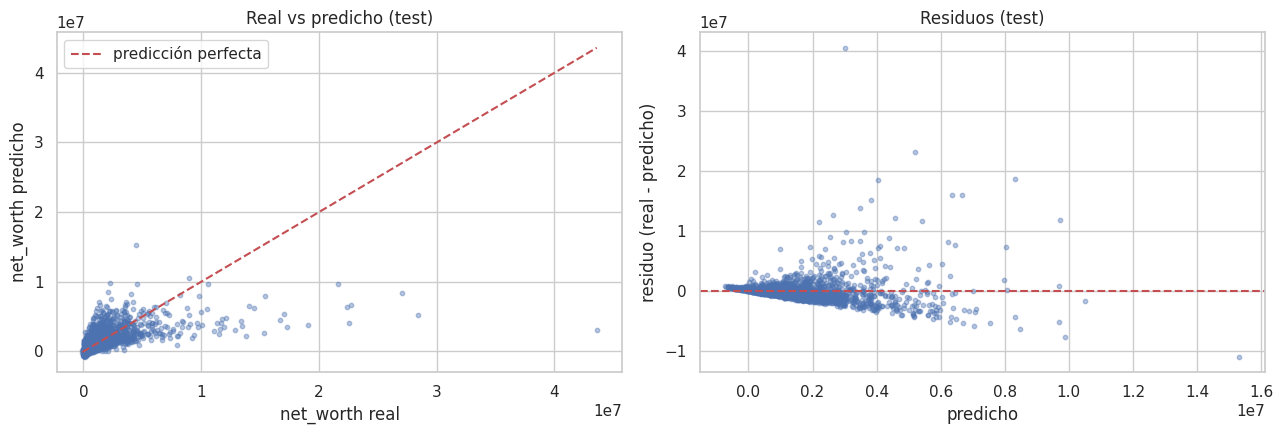

In [20]:

residuos = yTest - predTest
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))

ejes[0].scatter(yTest, predTest, alpha=0.4, s=10)
limites = [yTest.min(), yTest.max()]
ejes[0].plot(limites, limites, "r--", label="predicción perfecta")
ejes[0].set(xlabel="net_worth real", ylabel="net_worth predicho", title="Real vs predicho (test)")
ejes[0].legend()

ejes[1].scatter(predTest, residuos, alpha=0.4, s=10)
ejes[1].axhline(0, color="r", ls="--")
ejes[1].set(xlabel="predicho", ylabel="residuo (real - predicho)", title="Residuos (test)")

plt.tight_layout()
plt.show()


Link a GitHub: https://github.com/agustingonzalezgutierrez98/Proyecto-2-Regresion-Lineal.git